# Dry Run: Which Grape Is in the Glass?

*Can a model guess a wine's grape from a tasting note, and what is left when we take the obvious clues out?*

**Course:** Machine Learning, NaUKMA (mini-project)

**Team:** Alina Brukhanska, Milena Mashchenko, Viktoriia Boriak

## The short version

Wine reviewers love to name-drop. A tasting note might say *"this Riesling..."*, mention a valley, or tell you which winery made the bottle. A model that picks up on those words is not tasting anything. It is just reading the label.

So we ask a simple question: **if we strip those clues out of the reviews one step at a time, how much can a model still tell about the grape?**

Here is the plan, in four moves:

1. Take reviews of five grapes from the Wine Reviews dataset.
2. Make four versions of every review, from the original text (**L0**) to a text with grape names, other grapes, places and winery names removed (**L3**).
3. Train three classic models on each version, using the same data and the same folds for all of them.
4. Watch how the score changes, look at where the models go wrong, and say honestly what we can and cannot conclude.

This is not a hunt for the highest accuracy. What matters is that the experiment is fair, and that our conclusions only claim what the evidence supports.

## How this notebook is organized

We will have eleven steps. Each one has a home in the notebook, so you can find it without hunting. Sections marked **here** are in this part of the notebook. The rest are coming next.

| Section | What happens | Course step | Status |
|---|---|---|---|
| 1. The question | Main question, sub-questions, hypotheses, the plan at a glance | 1. Formulate the question | here |
| 2. Setup | Packages, imports, seed, folders, library versions | 11. Reproducibility | here |
| 3. The data | Source, license, loading, first look | 2. Inspect the data | here |
| 4. Cleaning and the shared sample | Remove missing values and duplicates, pick five grapes, balance the classes | 2. Inspect the data | next |
| 5. Splits and folds | DEV / MAIN split by winery, shared cross-validation folds | 6. Validation scheme | next |
| 6. Masking L0 to L3 | Word lists and the four text versions | 4. Preprocessing | next |
| 7. Metrics and baselines | Macro-F1 and friends, dummy baselines | 3. Baseline, 7. Metrics | next |
| 8. The three models | Pipelines, small tuning grids on DEV | 5. Models | next |
| 9. Results | One table, plots, extra checks | 8. Compare experiments | next |
| 10. Errors | Confusion matrices, top words, real examples | 9. Error analysis | next |
| 11. Conclusions | What we found, and the limits | 10. Limitations and conclusions | next |

## 1. The question *(course step 1)*

### Main question

> How well can we tell one of five grape varieties from the text of a tasting note, and how does that change when we remove the obvious clues one layer at a time?

The five grapes are **Chardonnay, Riesling, Pinot Noir, Cabernet Sauvignon and Syrah**. Two are white and three are red, which gives us something interesting to look at later in the mistakes.

### Sub-questions

- **RQ1. Masking.** How does the macro-F1 score move from L0 to L1 to L2 to L3? Do all three models react the same way? Which step hurts the most?
- **RQ2. Validation scheme** *(extra experiment)*. How different does logistic regression look under ordinary random cross-validation versus cross-validation that keeps each winery on one side only?
- **RQ3. Mistakes.** Which grapes get mixed up, and does that change after masking? Are reds mistaken for other reds more often than for whites?
- **RQ4. Words.** Which words push logistic regression towards each grape, on L0 and on L3? Are there still obvious clues left, and which taste words show up?
- **RQ5. Metadata** *(extra experiment)*. How far can we get using only geography, or only the taster's name, with no review text at all?

### What we expect (written down before we run anything)

- **H1.** Masking lowers the score on average, but the score stays above a random-guess baseline. It may not drop at every single step.
- **H2.** The last step, L2 to L3, changes the score noticeably. It removes places and winery names at the same time, so we will not be able to say which of the two matters more.
- **H3.** Reds get confused with other reds more than with whites.
- **H4.** Random cross-validation gives a higher score than winery-grouped cross-validation. A tiny difference, or the opposite, would also be a real result.
- **H5.** Logistic regression holds its own against the more complex SVD + boosting model. The simple model may well be enough.

If a hypothesis turns out wrong, that is a finding, not a failure.

### What counts as an answer

One main table: three models by four text versions, showing mean and standard deviation of macro-F1 over the same folds, with the baseline next to it. Then per-grape scores, confusion matrices, a handful of real mistakes read by hand, and a short conclusion for each question we actually ran.

### What we are *not* claiming

We sort reviews into five known grapes. We do not test whether a model can spot an unknown grape, measure how a wine really tastes, or show that a model "understands" flavor. Even after L3, hints can survive: indirect names, regional style, the way a particular taster writes. A score above the baseline on L3 does not prove the model learned to taste.

### The plan at a glance *(course steps 3 to 7)*

#### Four versions of every review

| Version | What we remove | What it tells us |
|---|---|---|
| **L0** | Nothing special, only basic cleanup shared by all versions | How well models do on the original text |
| **L1** | The five target grape names and their spelling variants | What changes without the direct answer |
| **L2** | Also the names of other grapes, from a fixed word list | Whether mentions of other grapes help |
| **L3** | Also place names, "where it's from" adjectives, and this review's own winery name | What is left after the widest masking |

The word lists are prepared before we run the experiments and do not depend on model results. Taste words such as *petrol*, *tannin* or *oak* are never removed just because they happen to go with a grape.

#### Three models, and why each one is here

| Model | Why it is in the study |
|---|---|
| TF-IDF + **Logistic Regression** | The readable one. Its coefficients show which words go with which grape. |
| TF-IDF + **Complement Naive Bayes** | Fast, built differently, and a classic for text. Shows whether we need anything fancier. |
| TF-IDF + **Truncated SVD** + **Hist Gradient Boosting** | A non-linear check. Does squeezing the text down and adding a more flexible model help? |

#### How we keep the test honest

- **Baselines.** Two dummy classifiers (always the most frequent class, and random guessing that follows class frequencies), scored on the same folds as everything else.
- **Group by winery.** Reviews from one winery share vocabulary and style. If some land in training and others in testing, the model can win by recognizing the winery. So each winery stays on one side of every split.
- **DEV and MAIN.** About a quarter of the wineries go to DEV, and we use it only for tuning. The rest is MAIN, where the final comparison happens. Once we have seen MAIN scores, we do not go back and tune.
- **No peeking.** TF-IDF and SVD live inside a scikit-learn `Pipeline`, so they are fitted from scratch on the training part of every fold and never see the test part.
- **Metric.** Macro-F1 is our main number because it treats all five grapes equally. We also report balanced accuracy and per-grape precision, recall and F1.
- **Folds.** Five folds, repeated three times if the running time allows. All models share the exact same folds. We decide on the number of repeats after timing things on DEV, before we touch MAIN. Anything we change after seeing MAIN scores gets labeled as after-the-fact.

## 2. Setup *(course step 11)*

This part runs on a normal laptop CPU. No GPU is needed. It checks that the packages are installed, loads them, and writes down which versions we used.

### 2.1 Are the packages here?

We only check. We do not reinstall anything, so Colab's own setup stays untouched. If something is missing, the message tells you what to install. Run the install in its own cell *before* the imports, and restart the runtime if you updated a package that was already loaded.

In [1]:
from importlib.util import find_spec

CORE_PACKAGES = {
    "numpy": "numpy",
    "pandas": "pandas",
    "scipy": "scipy",
    "scikit-learn": "sklearn",
    "matplotlib": "matplotlib",
}

missing_packages = [
    package for package, module in CORE_PACKAGES.items()
    if find_spec(module) is None
]

if missing_packages:
    raise ModuleNotFoundError(
        "Some packages are missing. Run this in a separate cell first:\n"
        "%pip install " + " ".join(missing_packages)
    )

print("All core packages are installed.")

All core packages are installed.


### 2.2 Imports

Importing is all we do here. No model is trained in this section.

In [2]:
from pathlib import Path
from datetime import datetime, timezone
from importlib import metadata
import hashlib
import json
import platform
import random
import re
import textwrap

# Data and plots
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# scikit-learn pieces
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import ComplementNB
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import (
    GroupShuffleSplit, StratifiedGroupKFold, StratifiedKFold, GridSearchCV,
)
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, f1_score,
    log_loss, precision_recall_fscore_support,
)

print("Imports done. Nothing has been trained yet.")

Imports done. Nothing has been trained yet.


### 2.3 One place for all settings

Every setting the team agreed on lives in this one cell. If we change something, we change it here and nowhere else.

A couple of notes:

- `N_JOBS = 1` is a safe, slow-and-steady default. It does not promise bit-for-bit identical results on every machine.
- Fixing `random.seed` and `np.random.seed` is not enough on its own. Whenever a specific algorithm takes a `random_state`, we pass `SEED` to it directly.
- `DATA_STAGE = "raw"` means we start from the original Kaggle file. Once the team's shared sample exists, we switch to `"sample"` and everyone reads the same file.

In [3]:
# Settings agreed by the whole team
SEED = 42
CLASSES = ["Chardonnay", "Riesling", "Pinot Noir", "Cabernet Sauvignon", "Syrah"]
LEVELS = ["L0", "L1", "L2", "L3"]
MODEL_NAMES = ["LogReg", "CompNB", "SVD_HGB"]

SAMPLE_CAP = 3000           # at most this many reviews per grape
DEV_GROUP_FRACTION = 0.25   # share of wineries that go to DEV
N_SPLITS = 5                # folds in cross-validation
N_REPEATS = 3               # repeats of the whole cross-validation
N_JOBS = 1
PRIMARY_SCORING = "f1_macro"

# Where the data comes from
DATA_STAGE = "raw"          # "raw" = original Kaggle CSV, "sample" = our shared sample
RAW_SOURCE = "local"        # "local" = file already uploaded, "kaggle" = download with kagglehub
RAW_FILENAME = "winemag-data-130k-v2.csv"
KAGGLE_DATASET = "zynicide/wine-reviews"
KAGGLE_VERSION = 4          # Kaggle, "Version 4"
EXPECTED_RAW_SHA256 = "52af2643c8ac29f010f0cc629dfbdda1c74aa0f332d11762af9ef3de4e567ac9"

# Quick sanity checks so a typo does not cost us an hour later
if len(CLASSES) != 5 or len(set(CLASSES)) != 5:
    raise ValueError("We need exactly five different grape classes.")
if DATA_STAGE not in {"raw", "sample"}:
    raise ValueError("DATA_STAGE must be 'raw' or 'sample'.")
if RAW_SOURCE not in {"local", "kaggle"}:
    raise ValueError("RAW_SOURCE must be 'local' or 'kaggle'.")
if not 0 < DEV_GROUP_FRACTION < 1:
    raise ValueError("DEV_GROUP_FRACTION must be between 0 and 1.")
if N_SPLITS < 2 or N_REPEATS < 1 or SAMPLE_CAP < 1:
    raise ValueError("N_SPLITS, N_REPEATS and SAMPLE_CAP have invalid values.")
if KAGGLE_VERSION is not None and (type(KAGGLE_VERSION) is not int or KAGGLE_VERSION < 1):
    raise ValueError("KAGGLE_VERSION must be a positive whole number, or None.")

random.seed(SEED)
np.random.seed(SEED)

print("Settings look fine. Seed:", SEED)
print("Grapes:", CLASSES)
print("Data mode:", DATA_STAGE, "/", RAW_SOURCE)

Settings look fine. Seed: 42
Grapes: ['Chardonnay', 'Riesling', 'Pinot Noir', 'Cabernet Sauvignon', 'Syrah']
Data mode: raw / local


### 2.4 Folders and plot style

Paths are relative to the folder the notebook runs from (in Colab that is usually `/content`). Nothing is searched for on your disk behind your back. Check the printed path to make sure it is what you expect.

Put the original CSV in that same folder. The shared sample will live in `data/`. The output folders below are created automatically.

In [4]:
PROJECT_ROOT = Path.cwd().resolve()
DATA_DIR = PROJECT_ROOT / "data"
MASKING_DIR = PROJECT_ROOT / "masking"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = PROJECT_ROOT / "figures"
SETUP_DIR = RESULTS_DIR / "setup"

for directory in [DATA_DIR, MASKING_DIR, RESULTS_DIR, FIGURES_DIR, SETUP_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

RAW_LOCAL_PATH = PROJECT_ROOT / RAW_FILENAME
SAMPLE_PATH = DATA_DIR / "wine_sample.csv"
SAMPLE_HASH_PATH = DATA_DIR / "wine_sample.sha256"

# Display settings only. They change how things look, never the data.
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 140)
plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "figure.dpi": 110,
    "savefig.dpi": 160,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
PLOT_COLOR = "#2a78d6"   # one calm blue for single-series charts
INK = "#52514e"          # muted gray for annotations

print("Project folder:", PROJECT_ROOT)
print("Looking for the original CSV at:", RAW_LOCAL_PATH)
print("Shared sample will be at:", SAMPLE_PATH)

Project folder: /content
Looking for the original CSV at: /content/winemag-data-130k-v2.csv
Shared sample will be at: /content/data/wine_sample.csv


### 2.5 Which versions did we use?

Different library versions can give slightly different numbers, so we write down what is installed. This list is also the starting point for the `requirements.txt` we will submit. It is a record of this run, not proof that the whole project is reproducible. We will test that with a clean run at the end.

In [5]:
STARTED_AT_UTC = datetime.now(timezone.utc).isoformat()

version_rows = [
    {"package": package, "version": metadata.version(package)}
    for package in CORE_PACKAGES
]
if DATA_STAGE == "raw" and RAW_SOURCE == "kaggle":
    if find_spec("kagglehub") is None:
        raise ModuleNotFoundError(
            "RAW_SOURCE='kaggle' needs kagglehub. Run in a separate cell:\n"
            "%pip install -q kagglehub"
        )
    version_rows.append({"package": "kagglehub", "version": metadata.version("kagglehub")})

versions = pd.DataFrame(version_rows)
versions.to_csv(SETUP_DIR / "package_versions.csv", index=False)
(SETUP_DIR / "requirements.startup.txt").write_text(
    "\n".join(f"{r['package']}=={r['version']}" for r in version_rows) + "\n",
    encoding="utf-8",
)

STARTUP_INFO = {
    "started_at_utc": STARTED_AT_UTC,
    "python": platform.python_version(),
    "platform": platform.platform(),
    "packages": dict(zip(versions["package"], versions["version"])),
    "seed": SEED,
    "classes": CLASSES,
    "levels": LEVELS,
    "sample_cap": SAMPLE_CAP,
    "dev_group_fraction": DEV_GROUP_FRACTION,
    "n_splits": N_SPLITS,
    "n_repeats": N_REPEATS,
    "n_jobs": N_JOBS,
    "primary_scoring": PRIMARY_SCORING,
    "data_stage": DATA_STAGE,
    "raw_source": RAW_SOURCE if DATA_STAGE == "raw" else None,
}

print("Python:", platform.python_version())
print(versions.to_string(index=False))
print("\nSaved to", SETUP_DIR)

Python: 3.13.18
     package version
       numpy   2.1.3
      pandas   2.2.3
       scipy  1.16.3
scikit-learn   1.6.1
  matplotlib  3.10.0

Saved to /content/results/setup


# 3. The data *(course step 2)*

### Where it comes from

**Wine Reviews**, shared on Kaggle by zynicide (Zack Thoutt): https://www.kaggle.com/datasets/zynicide/wine-reviews

According to the dataset page, the reviews were scraped from WineEnthusiast in June 2017, and scraped again on 22 November 2017. The file we use comes from the second scrape. That date tells us when the data was gathered, not when each review was written. We use the file `winemag-data-130k-v2.csv`.

The dataset page lists the license as **CC BY-NC-SA 4.0** (https://creativecommons.org/licenses/by-nc-sa/4.0/). If we share our sample, we keep the credit, the license and a note about what we changed.

### What each column is for

| Column | How we use it |
|---|---|
| `description` | **The input.** The text our models read. |
| `variety` | **The target.** The grape we are trying to predict. |
| `winery` | Used to group reviews when splitting, and as the winery name to mask on L3. The models never receive it as a feature. |
| `country`, `province`, `region_1`, `region_2` | For looking at the data and for the extra geography-only experiment. Not features of the main models. |
| `taster_name` | Only for the extra taster-only experiment. |
| `title`, `designation`, `points`, `price`, others | Left out of the main models. |

### How to get the file

- **Easiest:** download and unzip the CSV from Kaggle, then upload it with the Files panel in Colab into the folder printed in section 2.4. Keep `RAW_SOURCE = "local"`.
- **Or:** set `RAW_SOURCE = "kaggle"` and let `kagglehub` download it. Never put a Kaggle token in the notebook or on GitHub. Use your environment's secrets instead.
- **Once our shared sample exists:** set `DATA_STAGE = "sample"`. Everyone then reads the same CSV and checks it against the same hash, and the original file is no longer needed.

In [6]:
# Find the input file. We only locate it here; reading and cleaning come later.
if DATA_STAGE == "sample":
    INPUT_PATH = SAMPLE_PATH
    source_handle = None
elif RAW_SOURCE == "local":
    INPUT_PATH = RAW_LOCAL_PATH
    source_handle = None
else:
    import kagglehub

    source_handle = KAGGLE_DATASET
    if KAGGLE_VERSION is not None:
        source_handle += f"/versions/{KAGGLE_VERSION}"
    INPUT_PATH = Path(kagglehub.dataset_download(source_handle)).resolve() / RAW_FILENAME

if not INPUT_PATH.is_file():
    if DATA_STAGE == "raw":
        hint = ("Upload the unzipped CSV into the project folder with the Files panel, "
                "or set RAW_SOURCE = 'kaggle'.")
    else:
        hint = "Get data/wine_sample.csv and data/wine_sample.sha256 from the team repository."
    raise FileNotFoundError(f"Could not find {INPUT_PATH}. {hint}")

print("Found input file:", INPUT_PATH)
print("Size in bytes:", INPUT_PATH.stat().st_size)
if source_handle is not None:
    print("Kaggle handle:", source_handle)
    if KAGGLE_VERSION is None:
        print("Note: no Kaggle version is pinned yet. Pin one before we submit.")

Found input file: /content/winemag-data-130k-v2.csv
Size in bytes: 52908706


### 3.1 A fingerprint of the file

A SHA-256 hash is a short fingerprint of a file's exact bytes. If even one character changes, the hash changes. It tells us we are all working with the same file. It says nothing about the data's quality or license.

- For the **original** CSV, we compute the hash and record it. If nobody has pasted a reference hash into `EXPECTED_RAW_SHA256` yet, this is just a note, not a check.
- For our **shared sample**, a reference `.sha256` file is required, and the notebook stops if the hashes differ. We never overwrite the reference file just to make the check pass.

In [7]:
def sha256_file(path):
    """Hash a file in chunks, so we never hold a second copy in memory."""
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


INPUT_SHA256 = sha256_file(INPUT_PATH)

if DATA_STAGE == "sample":
    if not SAMPLE_HASH_PATH.is_file():
        raise FileNotFoundError(f"The reference hash file is missing: {SAMPLE_HASH_PATH}")
    expected_hash = SAMPLE_HASH_PATH.read_text(encoding="utf-8").strip().lower()
else:
    expected_hash = EXPECTED_RAW_SHA256.strip().lower() if EXPECTED_RAW_SHA256 else None

if expected_hash is not None:
    if re.fullmatch(r"[0-9a-f]{64}", expected_hash) is None:
        raise ValueError("A SHA-256 hash has exactly 64 hex characters.")
    if INPUT_SHA256 != expected_hash:
        raise ValueError("The file's hash does not match the reference. Check the file version.")
    hash_status = "matched_reference"
else:
    hash_status = "recorded_without_reference"

print("SHA-256:", INPUT_SHA256)
print("Status:", hash_status)

SHA-256: 52af2643c8ac29f010f0cc629dfbdda1c74aa0f332d11762af9ef3de4e567ac9
Status: matched_reference


### 3.2 Loading the table

We read the CSV into `input_df` and change nothing. In particular, we do not use `index_col=0`: the extra `Unnamed: 0` column is shown first, and we remove it on purpose in the cleaning step.

This is a structure check, not cleaning. In the raw file, missing values and duplicates are expected, and the cleaning step will count them. In the shared sample, they would be a problem, so the notebook checks for that.

In [8]:
input_df = pd.read_csv(INPUT_PATH, encoding="utf-8-sig", low_memory=False)

if input_df.empty:
    raise ValueError("The CSV has no rows.")

REQUIRED_COLUMNS = {"description", "variety", "winery"}
missing_columns = REQUIRED_COLUMNS - set(input_df.columns)
if missing_columns:
    raise ValueError(f"Required columns are missing: {sorted(missing_columns)}")

TARGET_COUNTS = input_df["variety"].value_counts().reindex(CLASSES, fill_value=0)
absent_classes = TARGET_COUNTS.index[TARGET_COUNTS.eq(0)].tolist()
if absent_classes:
    raise ValueError(f"These grapes are not in the file: {absent_classes}")

optional_columns = ["taster_name", "country", "province", "region_1", "region_2"]
missing_optional = [c for c in optional_columns if c not in input_df.columns]

if DATA_STAGE == "sample":
    # The shared sample must already be clean. These checks make sure of it.
    if "row_id" not in input_df.columns:
        raise ValueError("The sample needs a stable row_id column.")
    if input_df["row_id"].isna().any() or not input_df["row_id"].is_unique:
        raise ValueError("row_id must be filled in and unique.")
    if not input_df["variety"].isin(CLASSES).all():
        raise ValueError("The sample contains grapes outside our five classes.")
    for column in ["description", "variety", "winery"]:
        values = input_df[column]
        if values.isna().any() or values.astype(str).str.strip().eq("").any():
            raise ValueError(f"Empty values in required column '{column}'.")
    description_key = (input_df["description"].str.casefold()
                       .str.replace(r"\s+", " ", regex=True).str.strip())
    if description_key.duplicated().any():
        raise ValueError("The sample still has duplicate descriptions.")
    if TARGET_COUNTS.nunique() != 1 or TARGET_COUNTS.max() > SAMPLE_CAP:
        raise ValueError("Class counts in the sample do not match the agreed balancing.")
    print("Loaded the shared sample.")
else:
    print("Loaded the original, uncleaned file.")

if missing_optional:
    print("Heads up: these optional columns are not in the file:", missing_optional)

print("Rows:", len(input_df), "| Columns:", input_df.shape[1])
print("Column names:", input_df.columns.tolist())
input_df.head(3)

Loaded the original, uncleaned file.
Rows: 129971 | Columns: 14
Column names: ['Unnamed: 0', 'country', 'description', 'designation', 'points', 'price', 'province', 'region_1', 'region_2', 'taster_name', 'taster_twitter_handle', 'title', 'variety', 'winery']


,Unnamed: 0,country,description,designation,points,price,province,region_1,region_2,taster_name,taster_twitter_handle,title,variety,winery
0,0,Italy,"Aromas include tropical fruit, broom, brimstone and dried herb. The palate isn't overl...",Vulkà Bianco,87,NaN,Sicily & Sardinia,Etna,NaN,Kerin O’Keefe,@kerinokeefe,Nicosia 2013 Vulkà Bianco (Etna),White Blend,Nicosia
1,1,Portugal,"This is ripe and fruity, a wine that is smooth while still structured. Firm tannins ar...",Avidagos,87,15.0,Douro,NaN,NaN,Roger Voss,@vossroger,Quinta dos Avidagos 2011 Avidagos Red (Douro),Portuguese Red,Quinta dos Avidagos
2,2,US,"Tart and snappy, the flavors of lime flesh and rind dominate. Some green pineapple pok...",NaN,87,14.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Rainstorm 2013 Pinot Gris (Willamette Valley),Pinot Gris,Rainstorm


### 3.3 A first look

Before we change anything, let's get a feel for the data. This is only a first impression of the *original* file. The cleaned, balanced sample comes in the next section, so please do not read these counts as our final numbers.

In [9]:
# Which columns are there, what types are they, and how much is missing?
schema_overview = pd.DataFrame({
    "column": input_df.columns,
    "dtype": [str(input_df[c].dtype) for c in input_df.columns],
    "missing_count": input_df.isna().sum().to_numpy(),
    "missing_share": input_df.isna().mean().round(4).to_numpy(),
})
schema_overview.to_csv(SETUP_DIR / f"schema_{DATA_STAGE}.csv", index=False)
schema_overview

,column,dtype,missing_count,missing_share
0,Unnamed: 0,int64,0,0.0000
1,country,object,63,0.0005
2,description,object,0,0.0000
3,designation,object,37465,0.2883
4,points,int64,0,0.0000
5,price,float64,8996,0.0692
6,province,object,63,0.0005
7,region_1,object,21247,0.1635
8,region_2,object,79460,0.6114
9,taster_name,object,26244,0.2019


**Our five grapes.** How many reviews does each have, and how many different wineries are behind them? The winery count matters because we will group by winery when we split. A grape with only a handful of wineries would make grouped splitting hard.

In [10]:
def clean_key(series):
    """Lowercase and squeeze spaces. Used only for counting distinct names here."""
    return (series.dropna().astype(str).str.casefold()
            .str.replace(r"\s+", " ", regex=True).str.strip())


five = input_df[input_df["variety"].isin(CLASSES)].copy()
five["n_words"] = five["description"].fillna("").astype(str).str.split().str.len()

target_overview = pd.DataFrame({"variety": CLASSES})
target_overview["n_reviews"] = [int((five["variety"] == c).sum()) for c in CLASSES]
target_overview["n_wineries"] = [
    clean_key(five.loc[five["variety"] == c, "winery"]).replace("", np.nan).nunique()
    for c in CLASSES
]
target_overview["reviews_per_winery"] = (
    target_overview["n_reviews"] / target_overview["n_wineries"]
).round(1)
target_overview.to_csv(SETUP_DIR / f"target_counts_{DATA_STAGE}.csv", index=False)
target_overview

,variety,n_reviews,n_wineries,reviews_per_winery
0,Chardonnay,11753,3380,3.5
1,Riesling,5189,1041,5.0
2,Pinot Noir,13272,2658,5.0
3,Cabernet Sauvignon,9472,2918,3.2
4,Syrah,4142,1430,2.9


**Which labels count as our grapes?** We keep only reviews whose `variety` is exactly one of our five names. But the file also has look-alike labels: other names for the same grape, different grapes with a similar name, and blends. This table shows how many there are, so it is clear what we are leaving out.

In [11]:
# Which other labels look like one of our five grapes?
# "Look-alike" = a label that contains the grape's name (or a well-known second name)
# but is not exactly our label. We only keep reviews with the exact label.
LOOK_ALIKE_PATTERNS = {
    "Chardonnay": r"chardonnay",
    "Riesling": r"riesling",
    "Pinot Noir": r"pinot noir|pinot nero|sp[aä]tburgunder",
    "Cabernet Sauvignon": r"cabernet sauvignon|^cabernet$",
    "Syrah": r"syrah|shiraz|sirah",
}
SHOW_TOP = 10   # look-alike labels to print per grape; None = print all

label_counts = input_df["variety"].value_counts()

long_rows = []
for grape, pattern in LOOK_ALIKE_PATTERNS.items():
    hits = label_counts[label_counts.index.str.contains(pattern, case=False, regex=True, na=False)]
    hits = hits.drop(index=grape, errors="ignore")
    for label, n in hits.items():
        long_rows.append({"grape": grape, "look_alike_label": label, "n_reviews": int(n)})

look_alike_table = pd.DataFrame(long_rows, columns=["grape", "look_alike_label", "n_reviews"])
look_alike_table.to_csv(SETUP_DIR / f"look_alike_labels_{DATA_STAGE}.csv", index=False)

summary = (look_alike_table.groupby("grape")
           .agg(n_other_labels=("look_alike_label", "count"), n_reviews=("n_reviews", "sum"))
           .reindex(LOOK_ALIKE_PATTERNS.keys()).fillna(0).astype(int))
print(summary.to_string())

for grape in LOOK_ALIKE_PATTERNS:
    part = look_alike_table[look_alike_table["grape"] == grape]
    shown = part if SHOW_TOP is None else part.head(SHOW_TOP)
    print(f"\n{grape}: {len(part)} look-alike labels"
          + ("" if len(shown) == len(part) else f" (showing the {len(shown)} biggest)"))
    if len(shown):
        print(shown[["look_alike_label", "n_reviews"]].to_string(index=False))

                    n_other_labels  n_reviews
grape                                        
Chardonnay                      21        158
Riesling                         7         57
Pinot Noir                       5        275
Cabernet Sauvignon              22        649
Syrah                           44       2198

Chardonnay: 21 look-alike labels (showing the 10 biggest)
          look_alike_label  n_reviews
       Chardonnay-Viognier         35
   Chenin Blanc-Chardonnay         33
          Viura-Chardonnay         13
       Viognier-Chardonnay         12
Sauvignon Blanc-Chardonnay          8
       Chardonnay-Semillon          7
      Chardonnay-Sauvignon          6
          Pinot-Chardonnay          6
Chardonnay-Sauvignon Blanc          6
    Chardonnay-Pinot Blanc          5

Riesling: 7 look-alike labels
       look_alike_label  n_reviews
         Welschriesling         25
         White Riesling         13
  Johannisberg Riesling          9
Gewürztraminer-Riesling       

**What kind of look-alike is each label?** A table of names is not enough, because "same grape under another name" or "a different grape" is not something the data can tell us. It is wine knowledge, so we write it down by hand and give a source for every entry. Labels with a hyphen, such as *Syrah-Grenache*, are blends. Anything we have not classified is printed, and we must check it by hand before we move on.

Sources:
- [Syrah](https://en.wikipedia.org/wiki/Syrah): "Syrah, also known as Shiraz"; Petite Sirah is a different grape, a cross of Syrah and Peloursin.
- [Pinot noir](https://en.wikipedia.org/wiki/Pinot_noir): *Spätburgunder* (Germany) and *Pinot nero* (Italy) are other names for Pinot noir; *Schwarzriesling* is a name of Pinot Meunier, a different grape.
- [Riesling](https://en.wikipedia.org/wiki/Riesling): *White Riesling* and *Johannisberg Riesling* are other names for Riesling; Welschriesling is an unrelated variety (see also [Welschriesling](https://en.wikipedia.org/wiki/Welschriesling)).

In [12]:
# Hand-made classification of look-alike labels (sources are in the text cell above).
SAME_GRAPE_OTHER_NAME = {    # label in the file -> the class it belongs to
    "Shiraz": "Syrah",
    "Pinot Nero": "Pinot Noir",
    "Spätburgunder": "Pinot Noir",
    "White Riesling": "Riesling",
    "Johannisberg Riesling": "Riesling",
}
DIFFERENT_GRAPE = {          # label in the file -> what it is
    "Petite Sirah": "Durif, a cross of Syrah and Peloursin",
    "Welschriesling": "unrelated to Riesling",
    "Schwartzriesling": "a name of Pinot Meunier (the file spells it with a 't')",
}


def kind_of(label):
    if "-" in label:
        return "blend"
    if label in SAME_GRAPE_OTHER_NAME:
        return "same grape, other name"
    if label in DIFFERENT_GRAPE:
        return "different grape"
    return "UNCLASSIFIED"


look_alike_table["kind"] = look_alike_table["look_alike_label"].map(kind_of)
look_alike_table.to_csv(SETUP_DIR / f"look_alike_labels_{DATA_STAGE}.csv", index=False)

# Reviews per kind. A blend of two of our grapes appears under both, so rows are not additive.
kind_summary = (look_alike_table
                .pivot_table(index="grape", columns="kind", values="n_reviews",
                             aggfunc="sum", fill_value=0)
                .reindex(CLASSES).fillna(0).astype(int))
kind_summary.insert(0, "exact_label", TARGET_COUNTS.reindex(CLASSES).astype(int))
print("Reviews by kind of look-alike label")
print(kind_summary.to_string())

# What would we gain if we merged the same-grape names into our classes?
extra = (look_alike_table[look_alike_table["kind"] == "same grape, other name"]
         .groupby("grape")["n_reviews"].sum().reindex(CLASSES, fill_value=0))
merge_check = pd.DataFrame({
    "exact_label": TARGET_COUNTS.reindex(CLASSES).astype(int),
    "extra_if_merged": extra.astype(int),
})
merge_check["extra_percent"] = (100 * merge_check["extra_if_merged"]
                                / merge_check["exact_label"]).round(1)
merge_check["enough_without_merging"] = merge_check["exact_label"] >= SAMPLE_CAP
print("\nWould merging same-grape names help us reach the cap?")
print(merge_check.to_string())

unclassified = look_alike_table[look_alike_table["kind"] == "UNCLASSIFIED"]
if len(unclassified):
    print("\nPlease classify these labels by hand before we continue:")
    print(unclassified[["grape", "look_alike_label", "n_reviews"]].to_string(index=False))
else:
    print("\nEvery look-alike label is classified.")

Reviews by kind of look-alike label
kind                exact_label  UNCLASSIFIED  blend  different grape  same grape, other name
grape                                                                                        
Chardonnay                11753             2    156                0                       0
Riesling                   5189             0      9               26                      22
Pinot Noir                13272             0     22                0                     253
Cabernet Sauvignon         9472            13    636                0                       0
Syrah                      4142             0    592              770                     836

Would merging same-grape names help us reach the cap?
                    exact_label  extra_if_merged  extra_percent  enough_without_merging
Chardonnay                11753                0            0.0                    True
Riesling                   5189               22            0.4            

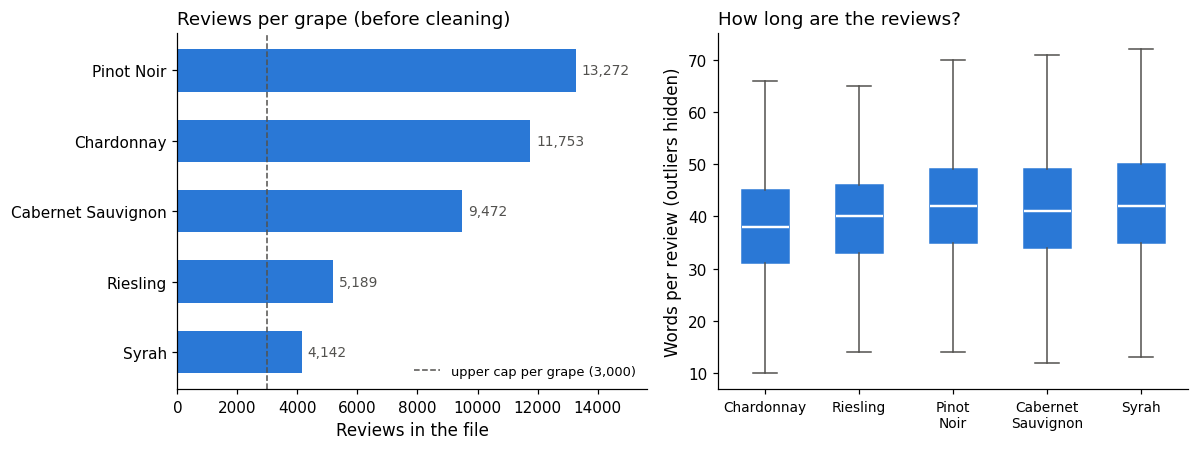

                      count  mean   std   min   25%   50%   75%    max
variety                                                               
Chardonnay          11753.0  38.3  10.9   3.0  31.0  38.0  45.0  104.0
Riesling             5189.0  41.0  11.9   6.0  33.0  40.0  46.0  125.0
Pinot Noir          13272.0  42.5  11.5   6.0  35.0  42.0  49.0  116.0
Cabernet Sauvignon   9472.0  41.9  12.6   8.0  34.0  41.0  49.0  135.0
Syrah                4142.0  42.7  12.0  10.0  35.0  42.0  50.0  115.0


In [13]:
# Figure: how many reviews per grape, and how long are the reviews?
fig, (ax_count, ax_len) = plt.subplots(1, 2, figsize=(11, 4.2))

order = target_overview.sort_values("n_reviews")
bars = ax_count.barh(order["variety"], order["n_reviews"], color=PLOT_COLOR, height=0.6)
ax_count.bar_label(bars, labels=[f"{n:,}" for n in order["n_reviews"]],
                   padding=4, color=INK, fontsize=9)
x_max = max(order["n_reviews"].max(), SAMPLE_CAP) * 1.18
ax_count.set_xlim(0, x_max)
ax_count.axvline(SAMPLE_CAP, color=INK, linestyle="--", linewidth=1,
                 label=f"upper cap per grape ({SAMPLE_CAP:,})")
ax_count.legend(frameon=False, loc="lower right", fontsize=8.5)
ax_count.set_xlabel("Reviews in the file")
ax_count.set_title("Reviews per grape (before cleaning)", loc="left")

length_data = [five.loc[five["variety"] == c, "n_words"] for c in CLASSES]
box = ax_len.boxplot(length_data, showfliers=False, patch_artist=True,
                     medianprops={"color": "white", "linewidth": 1.6})
for patch in box["boxes"]:
    patch.set(facecolor=PLOT_COLOR, edgecolor=PLOT_COLOR)
for line in box["whiskers"] + box["caps"]:
    line.set(color=INK, linewidth=1)
ax_len.set_xticks(range(1, len(CLASSES) + 1))
ax_len.set_xticklabels([c.replace(" ", "\n") for c in CLASSES], fontsize=9)
ax_len.set_ylabel("Words per review (outliers hidden)")
ax_len.set_title("How long are the reviews?", loc="left")

fig.tight_layout()
fig.savefig(FIGURES_DIR / "f1a_first_look_raw.png", bbox_inches="tight")
plt.show()

print(five.groupby("variety")["n_words"].describe().loc[CLASSES].round(1).to_string())

**What do the reviews actually look like?**

One random review per grape, selected with our fixed seed.
Labels are shown for interpretation. These examples illustrate
the original texts before cleaning and masking.

In [14]:
examples = (five.groupby("variety", group_keys=False)
            .sample(n=1, random_state=SEED)
            .set_index("variety").loc[CLASSES])

for grape, row in examples.iterrows():
    print(f"[{grape}]")
    print(textwrap.fill(str(row["description"]), width=100))
    print()

[Chardonnay]
For basic Chardonnay, this fits the bill as a good quaffer. Pithy citrus aromas lead to a zesty,
citrusy palate with flavors of green fruits, lemongrass and green herbs. It's lasting on the finish
and a touch ripe.

[Riesling]
Subtle hints of cereal and grain permeate throughout this medium-sweet Riesling, lending a savory
tone to honeyed grapefruit and apple flavors. While lacking great refinement, it offers fruit-
forward refreshment for casual settings. Drink now.

[Pinot Noir]
So delicious and easy to drink, it's complexities are almost unappreciated. Lush, ripe raspberry,
cherry and cola flavors flatter the palate, finished with smoky toast and exotic spices. Extra
points for crisp acidity and lovely tannins.

[Cabernet Sauvignon]
Soft with cranberry and red currant accents, this fairly priced wine is subtle in tannin and oak,
with a core of succulent black cherry and clove flavor. Approachable and round on the palate, it's a
good choice for big gatherings.

[Syrah]
D

**A quick peek at why masking matters.**

We count reviews containing their target variety's exact name,
using word boundaries and ignoring capitalization.

This check misses spelling variants and abbreviations. A matched
name is a potential clue, but it may refer to a comparison or blend
rather than directly identify the reviewed wine. These percentages
are pattern-match rates, not model accuracy.

In [15]:
def names_its_grape(texts, grape):
    pattern = re.compile(r"\b" + re.escape(grape) + r"\b", flags=re.IGNORECASE)
    return texts.fillna("").astype(str).apply(lambda t: bool(pattern.search(t)))


peek_rows = []
for grape in CLASSES:
    texts = five.loc[five["variety"] == grape, "description"]
    hit = names_its_grape(texts, grape)
    peek_rows.append({
        "variety": grape,
        "reviews": len(texts),
        "name_the_grape": int(hit.sum()),
        "share": round(float(hit.mean()), 3),
    })

name_peek = pd.DataFrame(peek_rows)
name_peek["share"] = (name_peek["share"] * 100).round(1).astype(str) + " %"
name_peek

,variety,reviews,name_the_grape,share
0,Chardonnay,11753,3215,27.4 %
1,Riesling,5189,2155,41.5 %
2,Pinot Noir,13272,2192,16.5 %
3,Cabernet Sauvignon,9472,682,7.2 %
4,Syrah,4142,1543,37.3 %


**Do short forms change the picture?** The table above counts only the exact grape name. Reviewers also use short forms (*Cab*, *Chard*) or a second name (*Shiraz*). Here we count those too. The short forms are a rough hand-picked list, not our final L1 word list, but they show how much the first count may miss.

In [16]:
SHORT_FORMS = {
    "Chardonnay": r"\bchardonnay\b|\bchard\b",
    "Riesling": r"\briesling\b",
    "Pinot Noir": r"\bpinot noir\b|\bpinot\b",
    "Cabernet Sauvignon": r"\bcabernet sauvignon\b|\bcabernet\b|\bcab\b",
    "Syrah": r"\bsyrah\b|\bshiraz\b",
}

rows = []
for grape in CLASSES:
    texts = five.loc[five["variety"] == grape, "description"].fillna("").astype(str)
    exact = texts.str.contains(r"\b" + re.escape(grape) + r"\b", case=False, regex=True)
    broad = texts.str.contains(SHORT_FORMS[grape], case=False, regex=True)
    rows.append({
        "variety": grape,
        "exact_name_%": round(100 * exact.mean(), 1),
        "with_short_forms_%": round(100 * broad.mean(), 1),
    })
short_form_check = pd.DataFrame(rows)
short_form_check["added_by_short_forms"] = (
    short_form_check["with_short_forms_%"] - short_form_check["exact_name_%"]
).round(1)
short_form_check

,variety,exact_name_%,with_short_forms_%,added_by_short_forms
0,Chardonnay,27.4,30.3,2.9
1,Riesling,41.5,41.5,0.0
2,Pinot Noir,16.5,28.1,11.6
3,Cabernet Sauvignon,7.2,40.5,33.3
4,Syrah,37.3,37.4,0.1


**Do broader patterns find more name mentions?**

For each variety, the bars compare exact-name matches with matches
from a broader pattern that includes selected short forms or aliases.

The largest increase is for Cabernet Sauvignon (7.2% to 40.5%),
followed by Pinot Noir (16.5% to 28.1%). These are exploratory
pattern-match rates, not model accuracy or verified label disclosures.
Broad terms such as `Pinot` and `Cabernet` can be ambiguous.

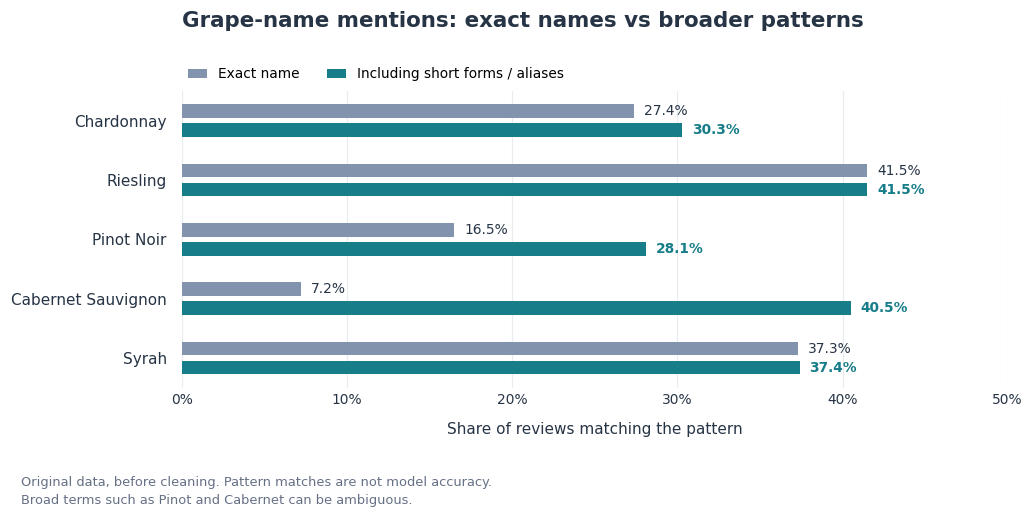

In [17]:
# Compact comparison using the values already calculated above.
plot_df = short_form_check.set_index("variety").loc[CLASSES]

exact = plot_df["exact_name_%"].to_numpy()
broad = plot_df["with_short_forms_%"].to_numpy()
y = np.arange(len(plot_df))

EXACT_COLOR = "#8294AD"
BROAD_COLOR = "#177E89"
TEXT_COLOR = "#263445"

fig, ax = plt.subplots(figsize=(9.5, 4.8), facecolor="white")
ax.set_facecolor("white")

# Two separate bars per variety: equal values remain easy to compare.
bar_height = 0.23
offset = 0.16

ax.barh(
    y - offset,
    exact,
    height=bar_height,
    color=EXACT_COLOR,
    label="Exact name",
    zorder=3,
)

ax.barh(
    y + offset,
    broad,
    height=bar_height,
    color=BROAD_COLOR,
    label="Including short forms / aliases",
    zorder=3,
)

for position, exact_rate, broad_rate in zip(y, exact, broad):
    ax.text(
        exact_rate + 0.6,
        position - offset,
        f"{exact_rate:.1f}%",
        va="center",
        fontsize=9,
        color=TEXT_COLOR,
    )
    ax.text(
        broad_rate + 0.6,
        position + offset,
        f"{broad_rate:.1f}%",
        va="center",
        fontsize=9,
        color=BROAD_COLOR,
        weight="bold",
    )

ax.set_yticks(y)
ax.set_yticklabels(plot_df.index, fontsize=10, color=TEXT_COLOR)
ax.set_ylim(len(plot_df) - 0.5, -0.5)

ax.set_xlim(0, 50)
ticks = np.arange(0, 51, 10)
ax.set_xticks(ticks)
ax.set_xticklabels([f"{value}%" for value in ticks], fontsize=9)

ax.set_xlabel(
    "Share of reviews matching the pattern",
    fontsize=10,
    color=TEXT_COLOR,
    labelpad=10,
)

ax.set_title(
    "Grape-name mentions: exact names vs broader patterns",
    loc="left",
    fontsize=14,
    weight="bold",
    color=TEXT_COLOR,
    pad=42,
)

ax.legend(
    loc="lower left",
    bbox_to_anchor=(0, 1.015),
    ncol=2,
    frameon=False,
    fontsize=9,
    borderaxespad=0,
    handlelength=1.4,
    columnspacing=2,
)

ax.set_axisbelow(True)
ax.grid(axis="x", color="#E9EDF2", linewidth=0.8)
ax.tick_params(axis="both", length=0, labelcolor=TEXT_COLOR)
ax.tick_params(axis="y", pad=10)

for spine in ax.spines.values():
    spine.set_visible(False)

fig.tight_layout(rect=(0, 0.13, 1, 1))

fig.text(
    0.025, 0.035,
    "Original data, before cleaning. Pattern matches are not model accuracy.\n"
    "Broad terms such as Pinot and Cabernet can be ambiguous.",
    fontsize=8.5,
    color="#667085",
    linespacing=1.5,
)

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

fig.savefig(
    FIGURES_DIR / f"f1b_name_cues_{DATA_STAGE}.png",
    dpi=200,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()

### 3.4 What we noticed in the original file

These observations describe the original CSV, before cleaning or balancing. They come from the saved outputs above; they are not results on the final sample or estimates of model performance.

**Size, missing values and class counts.** The file contains **129,971 reviews and 14 columns**, including the exported index `Unnamed: 0`. The five exact target labels account for **43,828 reviews**:

| Variety | Reviews before cleaning | Distinct normalized winery names | Mean words per review |
|---|---:|---:|---:|
| Chardonnay | 11,753 | 3,380 | 38.3 |
| Riesling | 5,189 | 1,041 | 41.0 |
| Pinot Noir | 13,272 | 2,658 | 42.5 |
| Cabernet Sauvignon | 9,472 | 2,918 | 41.9 |
| Syrah | 4,142 | 1,430 | 42.7 |

Every exact-label class currently exceeds the cap of 3,000, but this does not yet guarantee 3,000 usable reviews per class: missing or blank required fields, conflicting labels and duplicates still need to be checked during cleaning. The largest class is about 3.2 times the smallest, so this selected subset is not balanced yet.

The missing-value table reports **no pandas-detected missing values in `description` or `winery`**, and **one in `variety`** across the full file. This does not replace checks for blank or whitespace-only strings. Missing metadata include 8,996 prices, 21,247 `region_1` values, 79,460 `region_2` values and 26,244 taster names. Missing optional metadata will not by itself cause a review to be discarded from the main text experiment.

**Many winery names, but no validated folds yet.** The per-class counts range from 1,041 to 3,380 distinct winery names after case and whitespace normalization. Average reviews per winery within a class range from 2.9 to 5.0. These counts make grouped validation worth pursuing, but they do not establish that every future split will contain all five classes. We will check class coverage and group separation explicitly. The same winery may occur in several classes, so the per-class winery counts must not be added to obtain a total. Name normalization also does not guarantee that all aliases of a real winery have been resolved.

**Review lengths are broadly similar.** Mean lengths range from 38.3 to 42.7 whitespace-separated words, and medians range from 38 to 42. Chardonnay reviews are somewhat shorter on average. This is descriptive evidence about text length, not evidence that length predicts the grape or explains future errors. The boxplot hides outlier points for readability; no reviews have been removed because of their length.

**Potential name cues are common, and abbreviations matter.** The two checks above give:

| Variety | Exact name matched | Broader pattern matched | Increase (percentage points) |
|---|---:|---:|---:|
| Chardonnay | 27.4% | 30.3% | 2.9 |
| Riesling | 41.5% | 41.5% | 0.0 |
| Pinot Noir | 16.5% | 28.1% | 11.6 |
| Cabernet Sauvignon | 7.2% | 40.5% | 33.3 |
| Syrah | 37.3% | 37.4% | 0.1 |

The largest increase is for Cabernet Sauvignon, followed by Pinot Noir. This motivates checking spelling variants and abbreviations when preparing L1. However, broad terms such as `Pinot` and `Cabernet` are not uniquely specific to the target variety. Even an exact name can occur in a comparison or a discussion of a blend. These are pattern-match rates, not verified rates of reviews that reveal their own label, and not expected model accuracy. The exploratory patterns are not the final masking dictionary. The zero increase for Riesling is expected because its exact and broad patterns are identical here.

### Label choices and their limits

- **We retain exact target labels only.** The target labels are Chardonnay, Riesling, Pinot Noir, Cabernet Sauvignon and Syrah. We do not merge alternative labels, and we exclude separately labeled blends. This defines a restricted task; it does not establish that every retained wine is made entirely from a single grape.
- **Alternative names are not negligible for every class.** Under the manual mapping above, merging same-grape names would add 22 Riesling reviews (0.4%), 253 Pinot Noir reviews (1.9%) and 836 Syrah reviews (20.2%). There are no mapped additions for Chardonnay or Cabernet Sauvignon in this diagnostic. The raw exact-label counts already exceed the cap, so merging is not needed merely to reach 3,000 before cleaning. However, excluding names such as Shiraz can change which origins and styles are represented; it is a scope choice, not a guarantee of an equivalent sample.
- **The label audit is not complete.** The current code leaves three distinct labels unclassified: `Chardonnay Weissburgunder` (2 reviews), `Cabernet` (11) and `Cabernet Sauvignon Grenache` (2). They are excluded by the exact-label rule regardless of their eventual classification. We must document their treatment before presenting the auxiliary classification table as complete. In particular, the hyphen-based rule does not identify every possible blend label. Look-alike tables are pattern-based diagnostics, not an exhaustive catalogue of grape synonyms, and their per-grape totals can overlap.
- **Label filtering and text masking are separate decisions.** Excluding reviews labeled Shiraz does not justify leaving the word Shiraz in a Syrah review at L1. Verified alternative names of the five target grapes belong in the L1 dictionary; verified names of other grapes belong in L2. Ambiguous short forms need an explicit policy. The same frozen masking rules must be applied to every review without consulting its true class.
- **Our conclusions will concern a balanced, exact-label subset.** We will not claim performance for all wine varieties, all alternative labels or naturally occurring class frequencies. We rely on the dataset's labels rather than independently verifying each bottle's composition.


### 3.5 Where we are, and what is next

We have loaded the original CSV, checked its structure, recorded its SHA-256 and inspected missing values, class counts, winery-name counts, review lengths, selected label variants and potential name cues. The original `input_df` has not been changed. The temporary `five` table is a filtered copy for descriptive inspection, not the cleaned or balanced sample.

No cleaning, final sampling, DEV/MAIN splitting, masking, model fitting or predictive evaluation has been completed in this notebook yet. We therefore have no model scores or measured effects of masking to report.

**Two checks remain visible in the current saved outputs:**

The raw-file SHA-256 matches the configured reference
(`matched_reference`).

The auxiliary label audit still reports three unclassified labels:
`Chardonnay Weissburgunder`, `Cabernet`, and
`Cabernet Sauvignon Grenache`. They remain excluded under our
exact-label rule. Their treatment must be documented before
presenting the auxiliary audit as complete.

Next is **section 4: cleaning and the shared sample**, using the following order:

1. **Preserve provenance before filtering.** Start from a copy of the raw table and assign `source_row` and a stable `row_id` from the original record position. Remove the exported `Unnamed: 0` column deliberately; do not use it as a predictive feature.
2. **Apply the exact-label rule.** Retain the five agreed target labels and record the number of rows excluded. Rows with a missing target do not meet this rule.
3. **Check required fields.** Exclude missing or blank descriptions and winery names, recording removals at each step. Do not drop records merely because optional metadata are missing.
4. **Resolve duplicate descriptions.** Use a documented normalization for comparison. Among the retained target classes, remove all records whose normalized description has conflicting target labels. For the remaining repeated descriptions with the same label, keep the first record in original order. This detects duplicates under the chosen normalization, not every near-duplicate text.
5. **Create the balanced sample.** Select `min(SAMPLE_CAP, smallest cleaned class size)` records per class with the fixed seed (`SEED = 42`). Confirm class counts, nonempty required fields and unique IDs and normalized descriptions.
6. **Save the shared inputs and provenance.** Write `data/wine_sample.csv`, a hash-only `data/wine_sample.sha256`, the cleaning-flow table and a data README with source, version, attribution, license, selection rules and final counts. Verify the saved CSV before freezing it for the team.

If every class still has at least 3,000 records after cleaning, the sample will contain 15,000 reviews. Otherwise, all five classes will use the smaller available count. We do not report a final sample size until this step has actually run.

After the sample is frozen, participant 3 creates and checks the shared winery-grouped DEV/MAIN split and folds. Participant 2 can continue testing masking on synthetic examples in parallel, then inspect DEV examples once the split exists. Participant 1 prepares the cleaned-sample EDA. Masking dictionaries and tuning choices may use external sources and DEV, but must be frozen before MAIN evaluation; MAIN texts must not be inspected to expand the masking rules.
